# SARIMA · FinX model (Hong Rong)

**Target:** `target_next_ret` = next-day S&P 500 return
**Input:** `ret_index` only (the index's own past). SARIMA cannot use VIX, the 50 stocks or the indicators.
**Validation:** the shared walk-forward harness (`walk_forward` in `src/finx_common.py`), same 3 folds as every FinX model.

| Fold | Train | Test |
|---|---|---|
| 1 | 2021-01-04 to 2023 | 2024 |
| 2 | 2021-01-04 to 2024 | 2025 |
| 3 | 2021-01-04 to 2025 | 2026 to 21 Sep |

**Settings (fixed in advance, no tuning on test years):** seasonal period s = 5 trading days (one week), p, q in 0 to 2,
seasonal P, Q in 0 to 1, d = D = 0 (returns pass the ADF test), constant included. The order with the lowest AIC on the
training years is kept; fits whose optimiser did not converge are skipped. Parameters are then frozen and the model is
rolled forward one day at a time through the test year (no refit inside a fold). Code: `models/sarima_model.py`.

**Outputs:** `outputs/preds_sarima.csv` and `outputs/timing_sarima.json` (written by the harness);
`outputs/sarima/sarima_orders.csv`, `outputs/sarima/sarima_scores.csv` and the figures.

## 1. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import acf

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "src"), str(ROOT / "models")]
import config as C
import baselines as B                 # ARIMA, for the AIC comparison
import sarima_model as S              # fit / predict
from finx_common import FOLDS, fold_split, load_master, score, walk_forward

warnings.filterwarnings("ignore")
%matplotlib inline
pd.set_option("display.width", 160)
OUT = C.OUT_DIR / "sarima"
OUT.mkdir(parents=True, exist_ok=True)

## 2. Load the frozen master

In [2]:
master = load_master()                 # checksum and row count are checked on load
ret = master["ret_index"]
print(f"{len(master)} trading days: {master.index.min().date()} to {master.index.max().date()}")

1435 trading days: 2021-01-04 to 2026-09-21


## 3. Is there a weekly cycle to model?
SARIMA with s = 5 only helps if returns 5 or 10 trading days apart are correlated. The bars below are the autocorrelation
of daily returns on the largest training set (2021 to 2025); bars inside the grey band are not significant at 5%.

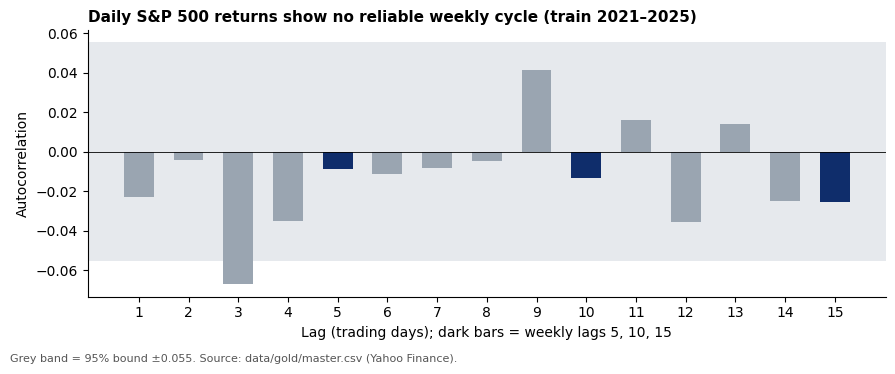

lag,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
acf,-0.0228,-0.0041,-0.0672,-0.0349,-0.009,-0.0114,-0.0081,-0.0048,0.0413,-0.0134,0.0157,-0.0359,0.0137,-0.0252,-0.0257
outside 95% band,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False


In [3]:
train_last = fold_split(master, FOLDS[-1])[0]["ret_index"]
LAGS = 15
r = acf(train_last, nlags=LAGS)[1:]
band = 1.96 / np.sqrt(len(train_last))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.axhspan(-band, band, color="#e6e9ed", lw=0)
colors = ["#0f2d6b" if k % S.SEASON == 0 else "#9aa5b1" for k in range(1, LAGS + 1)]
ax.bar(range(1, LAGS + 1), r, color=colors, width=0.6)
ax.axhline(0, color="black", lw=0.6)
ax.set_xticks(range(1, LAGS + 1))
ax.set_xlabel("Lag (trading days); dark bars = weekly lags 5, 10, 15")
ax.set_ylabel("Autocorrelation")
ax.set_title(f"Daily S&P 500 returns show no reliable weekly cycle (train {train_last.index.min().year}–{train_last.index.max().year})",
             fontsize=11, fontweight="bold", loc="left")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, -0.02, f"Grey band = 95% bound ±{band:.3f}. Source: data/gold/master.csv (Yahoo Finance).", fontsize=8, color="#555")
fig.tight_layout()
fig.savefig(OUT / "fig_sarima_acf.png", dpi=200, bbox_inches="tight")
plt.show()
pd.DataFrame({"lag": range(1, LAGS + 1), "acf": r.round(4), "outside 95% band": np.abs(r) > band}).set_index("lag").T

## 4. Walk-forward run (shared harness)
`walk_forward` fits once per fold, predicts every test day, times training and the latency of one next-day
prediction, and writes `preds_sarima.csv` and `timing_sarima.json`. The wrapper only keeps each fold's fitted model
so section 5 can report the chosen order without refitting. The grid has 36 fits per fold, so this takes under a minute.

In [4]:
fitted = []

def fit_and_keep(train):
    m = S.fit(train)
    fitted.append(m)
    return m

P, timing = walk_forward(fit_and_keep, S.predict, S.NAME, df=master)

[sarima] fold 2024: train 753 days, test 252 days, train 5.1s, 4.848 ms for one prediction


[sarima] fold 2025: train 1005 days, test 250 days, train 14.3s, 5.479 ms for one prediction


[sarima] fold 2026: train 1255 days, test 180 days, train 13.2s, 6.289 ms for one prediction


## 5. Order chosen per fold, and AIC vs ARIMA
"Best seasonal" is the lowest-AIC candidate that has at least one weekly term (P or Q = 1). ΔAIC = SARIMA − ARIMA on the
same training days: below 0 means SARIMA fits better. ARIMA comes from `src/baselines.py` (p, q in 0 to 3).
Ljung-Box p > 0.05 means no autocorrelation is left in SARIMA's residuals.

In [5]:
rows = []
for fold, m in zip(FOLDS, fitted):
    train = fold_split(master, fold)[0]
    a = B.arima_fit(train)
    g = m["grid"][m["grid"]["converged"]]
    seas = g[g["seasonal_order"].map(lambda s: s[0] + s[2] > 0)].nsmallest(1, "aic").iloc[0]
    lb = acorr_ljungbox(m["fit"].resid, lags=[5, 10], return_df=True)["lb_pvalue"]
    rows.append({"test_year": fold[0], "train_days": len(train), "SARIMA order": S.label(m),
                 "SARIMA AIC": round(m["aic"], 1),
                 "best seasonal": S.label({"order": seas["order"], "seasonal_order": seas["seasonal_order"]}),
                 "best seasonal AIC": round(seas["aic"], 1),
                 "ARIMA order": f"ARIMA{a['order']}", "ARIMA AIC": round(a["fit"].aic, 1),
                 "ΔAIC vs ARIMA": round(m["aic"] - a["fit"].aic, 1),
                 "LjungBox_p_lag5": round(lb.iloc[0], 3), "LjungBox_p_lag10": round(lb.iloc[1], 3),
                 "fits skipped (no convergence)": int((~m["grid"]["converged"]).sum())})
orders = pd.DataFrame(rows)
orders.to_csv(OUT / "sarima_orders.csv", index=False)
orders

,test_year,train_days,SARIMA order,SARIMA AIC,best seasonal,best seasonal AIC,ARIMA order,ARIMA AIC,ΔAIC vs ARIMA,LjungBox_p_lag5,LjungBox_p_lag10,fits skipped (no convergence)
0,2024,753,"SARIMA(0,0,0)(0,0,0,5)",-4639.7,"SARIMA(0,0,0)(1,0,0,5)",-4637.7,"ARIMA(0, 0, 0)",-4639.7,-0.0,0.780,0.574,1
1,2025,1005,"SARIMA(0,0,0)(0,0,0,5)",-6323.7,"SARIMA(0,0,0)(0,0,1,5)",-6322.0,"ARIMA(0, 0, 0)",-6323.7,-0.0,0.584,0.377,0
2,2026,1255,"SARIMA(0,0,0)(0,0,0,5)",-7827.7,"SARIMA(0,0,0)(1,0,0,5)",-7825.8,"ARIMA(0, 0, 3)",-7828.6,0.9,0.156,0.383,1


In [6]:
for _, o in orders.iterrows():
    print(f"{o['test_year']}: {o['SARIMA order']} AIC {o['SARIMA AIC']} vs {o['ARIMA order']} AIC {o['ARIMA AIC']} "
          f"(ΔAIC {o['ΔAIC vs ARIMA']:+.1f}); best model with a weekly term {o['best seasonal']} AIC {o['best seasonal AIC']}")
const = P.groupby("fold")["pred"].agg(["min", "max"]) * 100
print("\nForecast range per test year (% points):")
print(const.round(4).to_string())

2024: SARIMA(0,0,0)(0,0,0,5) AIC -4639.7 vs ARIMA(0, 0, 0) AIC -4639.7 (ΔAIC -0.0); best model with a weekly term SARIMA(0,0,0)(1,0,0,5) AIC -4637.7
2025: SARIMA(0,0,0)(0,0,0,5) AIC -6323.7 vs ARIMA(0, 0, 0) AIC -6323.7 (ΔAIC -0.0); best model with a weekly term SARIMA(0,0,0)(0,0,1,5) AIC -6322.0
2026: SARIMA(0,0,0)(0,0,0,5) AIC -7827.7 vs ARIMA(0, 0, 3) AIC -7828.6 (ΔAIC +0.9); best model with a weekly term SARIMA(0,0,0)(1,0,0,5) AIC -7825.8

Forecast range per test year (% points):
         min     max
fold                
2024  0.0379  0.0379
2025  0.0500  0.0500
2026  0.0535  0.0535


## 6. SARIMA vs ARIMA forecasts, 2026 test year
2026 is the one fold where the two models differ: ARIMA picked an MA(3) term, SARIMA kept the constant.

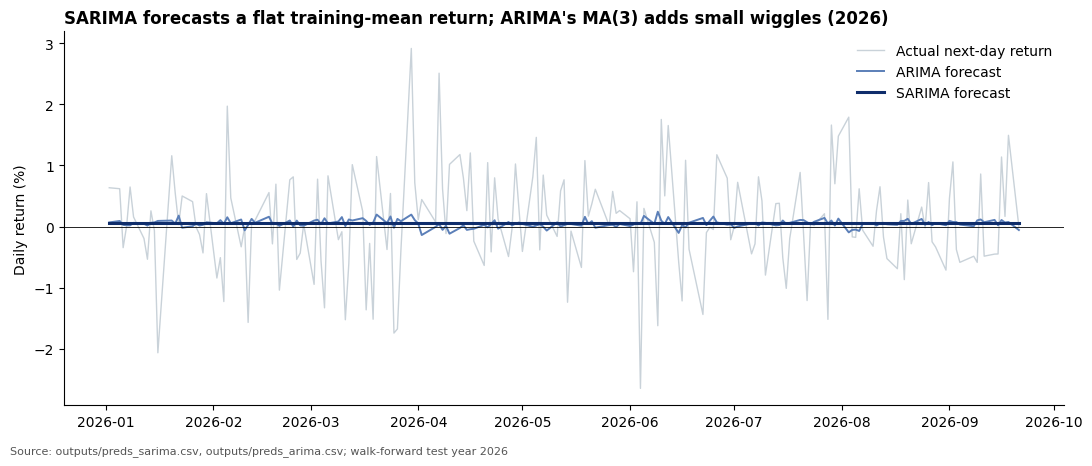

In [7]:
arima = pd.read_csv(C.OUT_DIR / "preds_arima.csv", index_col=0, parse_dates=True)
yr = FOLDS[-1][0]
p = P[P["fold"].astype(str) == yr]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(p.index, p["actual"] * 100, color="#c9d2d9", lw=1, label="Actual next-day return")
ax.plot(p.index, arima.loc[p.index, "pred"] * 100, color="#5b7fb8", lw=1.4, label="ARIMA forecast")
ax.plot(p.index, p["pred"] * 100, color="#0f2d6b", lw=2.2, label="SARIMA forecast")
ax.axhline(0, color="black", lw=0.6)
ax.set_ylabel("Daily return (%)")
ax.set_title(f"SARIMA forecasts a flat training-mean return; ARIMA's MA(3) adds small wiggles ({yr})",
             fontsize=12, fontweight="bold", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
fig.text(0.01, -0.02, f"Source: outputs/preds_sarima.csv, outputs/preds_arima.csv; walk-forward test year {yr}", fontsize=8, color="#555")
fig.tight_layout()
fig.savefig(OUT / f"fig_sarima_vs_arima_{yr}.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Scores
All test days pooled (not averaged per fold), then each fold. Skill vs naive = 1 − RMSE(SARIMA) ÷ RMSE(always 0).
"Forecast up (%)" is the share of days SARIMA predicted a positive return: at 100%, its Direction equals the
"always up" benchmark by construction.

In [8]:
def row(g, label):
    a = g["actual"]
    s = score(a, g["pred"], float(np.sqrt((a ** 2).mean())))
    up = 100 * (a[a != 0] > 0).mean()
    return {"test days": label, "n": len(g), "RMSE (%)": s["RMSE"] * 100, "MAE (%)": s["MAE"] * 100,
            "Direction (%)": s["Direction %"], "Always up (%)": up,
            "Skill vs naive (%)": s["Skill vs naive"] * 100, "Forecast up (%)": 100 * (g["pred"] > 0).mean()}

scores = pd.DataFrame([row(P, "pooled")] + [row(g, str(f)) for f, g in P.groupby("fold")]).round(3)
scores.to_csv(OUT / "sarima_scores.csv", index=False)
t = pd.Series({k: np.mean(list(v.values())) for k, v in timing.items() if k != "hardware"})
print(f"Train time per fold: {t['train_s']:.2f} s   Inference per day: {t['latency_ms_per_day']:.2f} ms   "
      f"Hardware: {timing['hardware']}")
scores

Train time per fold: 10.86 s   Inference per day: 5.54 ms   Hardware: {'cpu': 'arm', 'cores': 12, 'gpu': 'none'}


,test days,n,RMSE (%),MAE (%),Direction (%),Always up (%),Skill vs naive (%),Forecast up (%)
0,pooled,682,0.964,0.654,56.012,56.012,0.260,100.0
1,2024,252,0.796,0.589,56.746,56.746,0.409,100.0
2,2025,250,1.179,0.728,58.000,58.000,0.159,100.0
3,2026,180,0.837,0.642,52.222,52.222,0.347,100.0


In [9]:
s = scores.iloc[0]
print(f"SARIMA (all {int(s['n'])} test days): RMSE {s['RMSE (%)']:.3f}%  MAE {s['MAE (%)']:.3f}%  "
      f"Direction {s['Direction (%)']:.1f}%  Skill vs naive {s['Skill vs naive (%)']:+.2f}%")

SARIMA (all 682 test days): RMSE 0.964%  MAE 0.654%  Direction 56.0%  Skill vs naive +0.26%
